# Large-aperture metalens — amorphous-silicon pillars, no periodicity
A flat lens of amorphous-silicon pillars on a glass substrate, lit through the substrate
at a near-infrared wavelength. The pillars stand on a sub-wavelength square lattice and
each one's diameter sets the phase it imprints; the diameters follow the hyperbolic
focusing phase, so the lens is rotationally symmetric but nowhere periodic. The whole
aperture is solved in one full-vector Maxwell run with absorbing boundaries on every face.

The lens is described by its layout: the substrate is a box, and the pillars are one
GDSII layer of circles that the service extrudes to the pillar height. Each voxel that a
pillar's edge cuts takes the volume-weighted mean of the permittivity inside it, so the
diameter varies continuously on the grid instead of stepping by whole voxels.

The pillar library is calibrated first: one pillar in a periodic unit cell, solved for a
ladder of diameters, gives the transmitted phase and amplitude of each. The lens is built
from those calibrated pillars and solved as a whole, so pillar-to-pillar coupling, the
lens edge and the substrate are all in the solve. The air behind the lens is not
simulated: the field just behind the pillars is carried to the focus with the angular
spectrum, which is exact in a homogeneous medium. The solved volume only has to hold the
lens, and its voxel count grows with the aperture squared, not with the focal length.

Results: the pillar library, the lens layout, the field through and behind the pillars,
the focal cone, the focal spot against the diffraction limit, the measured focal length
and the focusing efficiency.

Size: 24 solves, the largest 216.1 Mvoxel including boundaries, 11.27 GB of memory (service estimate).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.patches import Polygon, Rectangle

from wavesimpro import Box, Gds, Medium, Setup, create_monitor, submit
from wsutils import apodise, circle, output_dir, propagate, write_gds

NAME = "mx_metalens_large_aperture"   # run name on the service and output folder
OUTPUT_DIR = output_dir(NAME)   # <repo root>/output/<NAME>

### Parameters
Lengths in μm. The z axis is the optical axis: the substrate fills its start and holds the
source sheet, then come the pillar layer and the exit plane in air. The absorbing boundary
behind the source continues the glass, so the substrate has no back face: a thin slab
would be a Fabry-Perot cavity with the lens as one mirror. A 32 μm lens at 40 nm voxels is the
default; for a 100 μm lens set `aperture = 100.0`, `focal_length = 87.0` and
`pixel_size = 0.05` (774 Mvoxel including boundaries, 57.7 GB, service estimate).

In [2]:
wavelength = 0.94           # near infrared, where amorphous silicon is transparent
pixel_size = 0.04
n_pillar = 3.6 + 0.01j      # amorphous silicon
n_substrate = 1.45          # fused silica
n_air = 1.0

aperture = 32.0             # lens diameter
focal_length = 28.0         # from the pillar tops
lattice_pitch = 0.6         # square lattice; below the wavelength in the substrate, so no diffraction orders
pillar_height = 0.72
diameters = np.unique(np.round(np.r_[0:0.17:0.02, 0.17:0.2151:0.005, 0.22:0.2501:0.01], 4))
#                             pillar diameters calibrated, 5 nm steps where the phase moves fastest;
#                             the phase completes a cycle by 240 nm
margin = 3.0                # bare substrate around the lens
taper = 2.5                 # Tukey ramp of the source sheet, inside the margin
boundary_width = 2.0        # absorbing boundary on every face, about 2 λ

z_src = 0.5                 # source sheet, inside the substrate
z_inc = (0.9, 1.14)         # two planes in the substrate where the incident amplitude is read
z_pillars0 = np.ceil(1.5 / pixel_size - 1e-9) * pixel_size   # top of the substrate, on a voxel face
z_pillars1 = z_pillars0 + pillar_height
z_exit = z_pillars1 + 1.0   # exit plane: its field is carried to the focus
z_end = z_exit + 0.6

SILICON = Medium("amorphous silicon", n_pillar)
GLASS = Medium("fused silica", n_substrate)
AIR = Medium("air", n_air)

k0 = 2 * np.pi / wavelength
NA = (aperture / 2) / np.hypot(aperture / 2, focal_length)
dl_fwhm = 0.51 * wavelength / NA
transverse = aperture + 2 * margin
nx = ny = int(round(transverse / pixel_size))
nz = int(round(z_end / pixel_size))
n_pitch = int(round(lattice_pitch / pixel_size))
if abs(n_pitch * pixel_size - lattice_pitch) > 1e-9:
    raise ValueError("the lattice pitch must be a whole number of voxels")
z = (np.arange(nz) + 0.5) * pixel_size


def voxel(position):
    """Index of the voxel that holds a position along z."""
    return int(np.floor(position / pixel_size + 1e-9))


iz_src, iz_exit = voxel(z_src), voxel(z_exit)
iz_inc = [voxel(v) for v in z_inc]
i_axis = nx // 2            # the optical axis, in x and in y: lattice site at the centre of the aperture

nb = int(round(boundary_width / pixel_size))
print(f"Lens: aperture {aperture} um, f {focal_length} um, NA {NA:.2f}; pitch {lattice_pitch} um = {n_pitch} voxels, "
      f"pillars {pillar_height} um tall from z = {z_pillars0:.2f} um")
print(f"Domain {transverse} x {transverse} x {z_end:.2f} um = {nx}x{ny}x{nz} voxels "
      f"({nx * ny * nz / 1e6:.0f} Mvoxel without boundaries), {wavelength / pixel_size:.0f} voxels per vacuum wavelength")
print(f"With the absorbing boundaries: {(nx + 2 * nb) * (ny + 2 * nb) * (nz + 2 * nb) / 1e6:.0f} Mvoxel")

Lens: aperture 32.0 um, f 28.0 um, NA 0.50; pitch 0.6 um = 15 voxels, pillars 0.72 um tall from z = 1.52 um
Domain 38.0 x 38.0 x 3.84 um = 950x950x96 voxels (87 Mvoxel without boundaries), 23 voxels per vacuum wavelength
With the absorbing boundaries: 216 Mvoxel


### Geometry
The substrate is a box of glass from the domain's first face to the foot of the pillars;
its faces lie on voxel faces, so it is drawn without averaging. The pillars are circles
(48-sided polygons of the same area) in one GDSII layer, extruded by the service from the
substrate top to the pillar height, with sub-pixel averaging: each voxel a pillar edge
cuts takes the volume-weighted mean of the permittivity inside it. A library cell and the
lens are drawn by the same function.

In [3]:
def world(i, n):
    """Domain-centred coordinate of the centre of voxel i on an n-voxel axis."""
    return (i + 0.5 - n / 2) * pixel_size


def substrate(n):
    """Glass across an n x n-voxel cross-section, from the domain's first face to the substrate top."""
    bottom, top = -nz * pixel_size / 2, z_pillars0 - nz * pixel_size / 2
    return Box(n=GLASS, name="substrate", center=(0.0, 0.0, (bottom + top) / 2),
               size=(n * pixel_size, n * pixel_size, top - bottom), subpixel=False)


def outlines(sites, c):
    """One circle per site (x index, y index, diameter), in um from the centre of voxel (c, c)."""
    return [circle(((i - c) * pixel_size, (j - c) * pixel_size), d / 2) for i, j, d in sites if d > 0]


def pillars(sites, n, path):
    """Write the pillars of an n x n-voxel cross-section to a GDS file and return the layer that places them."""
    c = n // 2
    polygons = outlines(sites, c)
    write_gds(path, polygons, layer=1)
    corners = np.vstack(polygons)
    middle = (np.round(corners.min(0), 4) + np.round(corners.max(0), 4)) / 2   # the service puts this point at `center`
    return Gds(n=SILICON, name="pillars", path=path, center=(world(c, n) + middle[0], world(c, n) + middle[1], 0.0),
               layers={1: (SILICON, pillar_height, z_pillars0 - nz * pixel_size / 2)}, subpixel=True)


def sheet(n, tapered):
    """y-polarised source sheet across an n x n-voxel cross-section, launching towards +z."""
    source = (np.ones((1, n, n, 1), dtype=np.complex64), (1, 0, 0, iz_src))
    return apodise(source, axes="xy", alpha=2 * taper / (n * pixel_size)) if tapered else source

### Library: transmitted phase and amplitude of each diameter
One pillar in a cell that repeats periodically in x and y, lit by the same source as the
lens; the transmitted field is averaged over the cell on the exit plane. Phase and
amplitude are relative to the empty cell, so the first entry means "no pillar". Pillars
that transmit less than 60% sit on a resonance and are left out of the lens; the
remaining phases must cover the circle with no gap wider than 0.2 of a cycle, or the
run stops here rather than solve a lens that cannot focus.

In [4]:
def library_setup(diameter):
    setup = Setup(wavelength, pixel_size, (n_pitch, n_pitch, nz), boundary_width=boundary_width,
                  periodic=(True, True, False), background=AIR, name=f"library {diameter * 1e3:.0f} nm", folder=NAME)
    setup.add(substrate(n_pitch), sheet(n_pitch, tapered=False))
    if diameter > 0:
        c = n_pitch // 2
        setup.add(pillars([(c, c, diameter)], n_pitch, f"{OUTPUT_DIR}/metalens_large_cell_{diameter * 1e3:03.0f}nm.gds"))
    return setup


library_runs = [submit(library_setup(d)) for d in diameters]
transmitted = []
for d, run in zip(diameters, library_runs):
    run.wait()
    transmitted.append(run.get_field()[1, :, :, iz_exit].mean())
    t = transmitted[-1] / transmitted[0]
    print(f"  d = {d * 1e3:3.0f} nm: {run.iterations} iterations, residual {run.residual_norm:.1e}, "
          f"|t| = {abs(t):.3f}, phase = {np.mod(np.angle(t), 2 * np.pi) / (2 * np.pi):.3f} cycles")
t = np.array(transmitted) / transmitted[0]
phases, amplitudes = np.mod(np.angle(t), 2 * np.pi), np.abs(t)

usable = amplitudes >= 0.6
covered = np.sort(phases[usable])
largest_gap = np.max(np.diff(np.append(covered, covered[0] + 2 * np.pi))) / (2 * np.pi)
print(f"{usable.sum()} of {len(diameters)} diameters transmit at least 60%; "
      f"largest gap between their phases {largest_gap:.2f} cycles; lowest |t| {amplitudes.min():.2f} "
      f"at {diameters[np.argmin(amplitudes)] * 1e3:.0f} nm")
if largest_gap > 0.2:
    raise RuntimeError("the usable pillars leave a gap in the phase circle: change the pitch or the pillar height")


  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 6ce31ecb-f029-45e3-bfa7-c6d38371f29e
  Version   : 824b85fa-77a2-4b3f-a58a-0b29a66eca5f
  Command   : 57d6e250-0164-42ad-9db7-e01b670d4a06
  Mode      : Maxwell (vectorial)
  Domain    : 15x15x96 voxels  lambda=0.94 um  dx=0.040 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------
  d =   0 nm: 61 iterations, residual 7.8e-07, |t| = 1.000, phase = 0.000 cycles

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : fbde0280-8db2-4660-b71d-a73ed7e8759c
  Version   : c7c8961c-9e23-4204-994f-1eaffb2d8a8d
  Command   : 37a22e2f-5a3a-4657-8461-ab3c64c98cee
  Mode      : Maxwell (vectorial)
  Domain    : 15x15x96 voxels  lambda=0.94 um  dx=0.040 um


### The lens
Every lattice site inside the aperture gets the usable diameter whose phase is nearest to
the focusing phase −k₀(√(r² + f²) − f) at that radius. The phase steps between
neighbouring diameters are the only approximation of the design; the solve below sees the
lens as it is.

In [5]:
def design():
    """(x index, y index, diameter) of every lattice site in the aperture."""
    m = int(aperture / 2 / lattice_pitch)
    rows = i_axis + np.arange(-m, m + 1) * n_pitch
    choices = np.flatnonzero(usable)
    sites = []
    for i in rows:
        for j in rows:
            r = np.hypot(i - i_axis, j - i_axis) * pixel_size
            if r > aperture / 2:
                continue
            target = -k0 * (np.hypot(r, focal_length) - focal_length)
            k = choices[np.argmin(np.abs(np.angle(np.exp(1j * (phases[choices] - target)))))]
            sites.append((int(i), int(j), float(diameters[k])))
    return sites


sites = design()
lens_pillars = pillars(sites, nx, f"{OUTPUT_DIR}/metalens_large_pillars.gds")
placed = np.array([((i - i_axis) * pixel_size, (j - i_axis) * pixel_size, d) for i, j, d in sites])
print(f"{len(placed)} lattice sites in the aperture, {np.sum(placed[:, 2] > 0)} pillars")

2233 lattice sites in the aperture, 2232 pillars


### Figure 1: layout
The pillar diameter at every lattice site (the rings are the phase wrapping every 2π),
the GDS polygons at the centre, and a side cut through the axis.

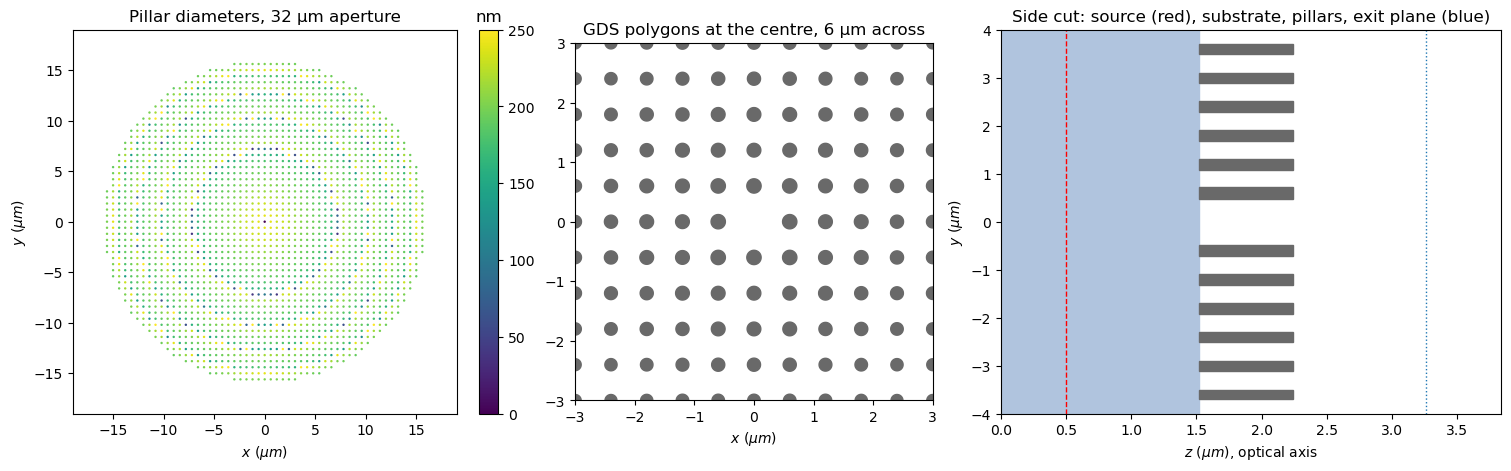

In [6]:
fig, (ax_a, ax_b, ax_c) = plt.subplots(1, 3, figsize=(15, 4.6), constrained_layout=True,
                                       gridspec_kw={"width_ratios": [1.25, 1, 1.4]})
sc = ax_a.scatter(placed[:, 0], placed[:, 1], c=placed[:, 2] * 1e3, s=3, cmap="viridis", linewidths=0)
ax_a.set_xlim(-transverse / 2, transverse / 2); ax_a.set_ylim(-transverse / 2, transverse / 2); ax_a.set_aspect("equal")
ax_a.set_xlabel(r"$x~(\mu m)$"); ax_a.set_ylabel(r"$y~(\mu m)$")
ax_a.set_title(f"Pillar diameters, {aperture:.0f} μm aperture")
fig.colorbar(sc, ax=ax_a, fraction=0.046).ax.set_title("nm")

near = [s for s in sites if max(abs(s[0] - i_axis), abs(s[1] - i_axis)) * pixel_size < 3.5]
for polygon in outlines(near, i_axis):
    ax_b.add_patch(Polygon(polygon, color="dimgrey"))
ax_b.set_xlim(-3, 3); ax_b.set_ylim(-3, 3); ax_b.set_aspect("equal")
ax_b.set_xlabel(r"$x~(\mu m)$"); ax_b.set_title("GDS polygons at the centre, 6 μm across")

ax_c.add_patch(Rectangle((0, -4), z_pillars0, 8, color="lightsteelblue"))
for i, j, d in sites:
    if i == i_axis and d > 0 and abs(j - i_axis) * pixel_size < 4:
        ax_c.add_patch(Rectangle((z_pillars0, (j - i_axis) * pixel_size - d / 2), pillar_height, d, color="dimgrey"))
ax_c.axvline(z_src, color="red", ls="--", lw=1)
ax_c.axvline(z[iz_exit], color="tab:blue", ls=":", lw=1)
ax_c.set_xlim(0, nz * pixel_size); ax_c.set_ylim(-4, 4)
ax_c.set_xlabel(r"$z~(\mu m)$, optical axis"); ax_c.set_ylabel(r"$y~(\mu m)$")
ax_c.set_title("Side cut: source (red), substrate, pillars, exit plane (blue)")
fig.savefig(f"{OUTPUT_DIR}/metalens_large_setup.png", dpi=200)

### Figure 2: library

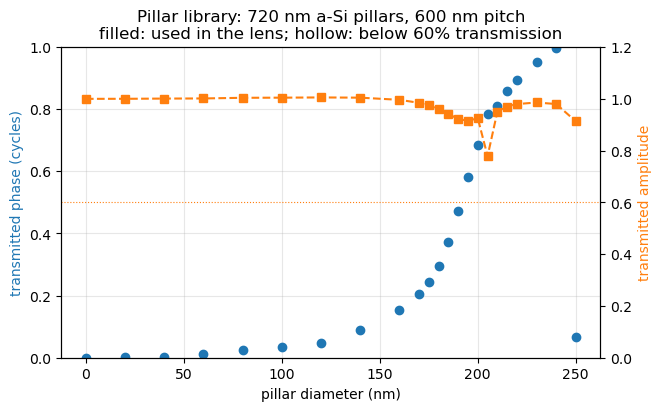

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4), constrained_layout=True)
ax.plot(diameters[usable] * 1e3, phases[usable] / (2 * np.pi), "o", color="tab:blue")
ax.plot(diameters[~usable] * 1e3, phases[~usable] / (2 * np.pi), "o", mfc="none", color="tab:blue")
ax.set_ylabel("transmitted phase (cycles)", color="tab:blue")
ax.set_ylim(0, 1)
ax2 = ax.twinx()
ax2.plot(diameters * 1e3, amplitudes, "s--", color="tab:orange")
ax2.axhline(0.6, color="tab:orange", ls=":", lw=0.8)
ax2.set_ylabel("transmitted amplitude", color="tab:orange"); ax2.set_ylim(0, 1.2)
ax.set_title(f"Pillar library: {pillar_height * 1e3:.0f} nm a-Si pillars, {lattice_pitch * 1e3:.0f} nm pitch\n"
             "filled: used in the lens; hollow: below 60% transmission")
ax.set_xlabel("pillar diameter (nm)")
ax.grid(True, alpha=0.3)
fig.savefig(f"{OUTPUT_DIR}/metalens_large_library.png", dpi=200)

### Solve
A y-polarised plane wave, tapered to zero inside the margin, launched in the substrate
towards the pillars. Three monitors bring back only what is needed: a slab in the glass
for the incident amplitude, the exit plane, and the y–z cut through the axis.

In [8]:
monitors = [
    create_monitor(name="incident", center_x=0.0, center_y=0.0, center_z=world((iz_inc[0] + iz_inc[1]) / 2, nz),
                   size_x=transverse, size_y=transverse, size_z=(iz_inc[1] - iz_inc[0] + 1) * pixel_size),
    create_monitor(name="exit", center_x=0.0, center_y=0.0, center_z=world(iz_exit, nz),
                   size_x=transverse, size_y=transverse, size_z=pixel_size),
    create_monitor(name="axial", center_x=world(i_axis, nx), center_y=0.0, center_z=0.0,
                   size_x=pixel_size, size_y=transverse, size_z=nz * pixel_size),
]
lens = Setup(wavelength, pixel_size, (nx, ny, nz), boundary_width=boundary_width,
             periodic=(False, False, False), background=AIR, name="lens", folder=NAME)
lens.add(substrate(nx), lens_pillars, sheet(nx, tapered=True), *monitors)

print("\nSolving the lens...")
run = submit(lens).wait()
print(f"{run.iterations} iterations, residual {run.residual_norm:.1e}")
u_inc, u_exit, u_axial = run.get_monitors()


def plane(u, axis):
    """A one-voxel-thick monitor as a plane: its middle voxel along the thin axis, unless that axis was already dropped."""
    return u if u.ndim == 3 else np.take(u, u.shape[axis] // 2, axis=axis)


u_exit = plane(u_exit, 3)     # (3, nx, ny): the exit plane is thin in z
u_axial = plane(u_axial, 1)   # (3, ny, nz): the axial cut is thin in x
np.savez(f"{OUTPUT_DIR}/metalens_large_fields.npz", exit_plane=u_exit, axial=u_axial, incident=u_inc,
         diameters=diameters, phases=phases, amplitudes=amplitudes, sites=np.array(sites))


Solving the lens...

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 8c404bc6-1021-483b-a610-684096d78c66
  Version   : d2ca5a29-8776-431d-a32b-4ba7ac38d644
  Command   : d45c5a04-5c72-4804-b9af-fabae836c888
  Mode      : Maxwell (vectorial)
  Domain    : 950x950x96 voxels  lambda=0.94 um  dx=0.040 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------
1359 iterations, residual 9.9e-07


### Incident amplitude
In the glass the field is the incident wave plus what the lens reflects. Its mean over
the central aperture on the first and last plane of the slab separates the two, and the
incident amplitude normalises everything below.

In [9]:
centre = (np.abs(np.arange(nx) - i_axis) * pixel_size < aperture / 4)
sel = centre[:, None] & centre[None, :]
e = np.array([u_inc[1, :, :, 0][sel].mean(), u_inc[1, :, :, -1][sel].mean()])
dz = (u_inc.shape[3] - 1) * pixel_size
k_glass = n_substrate * k0
forward, backward = np.linalg.solve([[1, 1], [np.exp(1j * k_glass * dz), np.exp(-1j * k_glass * dz)]], e)
e_inc = abs(forward)
print(f"Incident |E| in the glass {e_inc:.4f}; reflected / incident {abs(backward) / e_inc:.3f}")

Incident |E| in the glass 0.0021; reflected / incident 0.031


### From the exit plane to the focus
`propagate` carries the exit-plane field a distance d through air by its angular
spectrum. The on-axis intensity against distance locates the focus; the row of each
plane along y through the axis builds the focal cone.

In [10]:
distances = np.linspace(0, 1.5 * focal_length, 300)
cone = np.empty((len(distances), ny))
for k, d in enumerate(distances):
    row = propagate(u_exit, pixel_size, wavelength, d)[:, i_axis, :]
    cone[k] = np.sum(np.abs(row) ** 2, axis=0)
on_axis = cone[:, i_axis]
k_focus = int(np.argmax(np.where(distances > 2.0, on_axis, 0)))
d_focus = distances[k_focus]
f_measured = (z[iz_exit] - z_pillars1) + d_focus
print(f"Focus {f_measured:.2f} um from the pillar tops (design {focal_length} um)")

Focus 27.43 um from the pillar tops (design 28.0 um)


### Figure 3: field through the lens and the focal cone

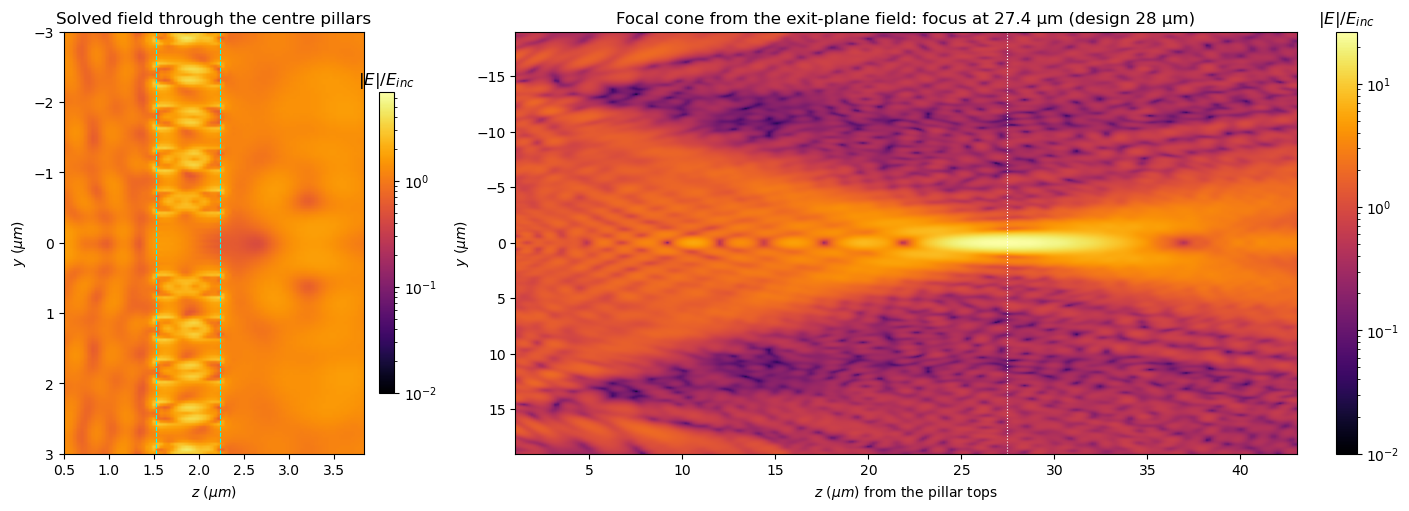

In [11]:
amp_axial = np.sqrt(np.sum(np.abs(u_axial) ** 2, axis=0)) / e_inc
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True, gridspec_kw={"width_ratios": [1, 2.6]})
im = ax_a.imshow(amp_axial, cmap="inferno", extent=[0, nz * pixel_size, transverse / 2, -transverse / 2], aspect="auto",
                 norm=colors.LogNorm(vmin=1e-2, vmax=amp_axial.max()))
ax_a.set_xlim(z_src, nz * pixel_size); ax_a.set_ylim(3, -3)
ax_a.axvline(z_pillars0, color="cyan", lw=0.8, ls="--"); ax_a.axvline(z_pillars1, color="cyan", lw=0.8, ls="--")
ax_a.set_xlabel(r"$z~(\mu m)$"); ax_a.set_ylabel(r"$y~(\mu m)$")
ax_a.set_title("Solved field through the centre pillars")
fig.colorbar(im, ax=ax_a, fraction=0.05).ax.set_title(r"$|E|/E_{inc}$")
cone_amp = np.sqrt(cone) / e_inc
im = ax_b.imshow(cone_amp.T, cmap="inferno", aspect="auto",
                 extent=[z[iz_exit] - z_pillars1, z[iz_exit] - z_pillars1 + distances[-1], transverse / 2, -transverse / 2],
                 norm=colors.LogNorm(vmin=1e-2, vmax=cone_amp.max()))
ax_b.axvline(f_measured, color="white", lw=0.8, ls=":")
ax_b.set_xlabel(r"$z~(\mu m)$ from the pillar tops"); ax_b.set_ylabel(r"$y~(\mu m)$")
ax_b.set_title(f"Focal cone from the exit-plane field: focus at {f_measured:.1f} μm (design {focal_length:.0f} μm)")
fig.colorbar(im, ax=ax_b, fraction=0.03).ax.set_title(r"$|E|/E_{inc}$")
fig.savefig(f"{OUTPUT_DIR}/metalens_large_field.png", dpi=200)

### Figure 4: focal spot
Intensity in the focal plane, its cut along the polarisation (y) against the
diffraction-limited width 0.51 λ/NA, and the focusing efficiency: the power inside a
circle of three FWHM radii around the focus, over the power incident on the aperture
(|E|² times area, times the refractive index on the glass side).

Focal spot FWHM 1000 nm (diffraction limit 966 nm); focusing efficiency 0.666; peak intensity 696 x incident
Saved output/mx_metalens_large_aperture/metalens_large_setup.png, _library.png, _field.png, _spot.png


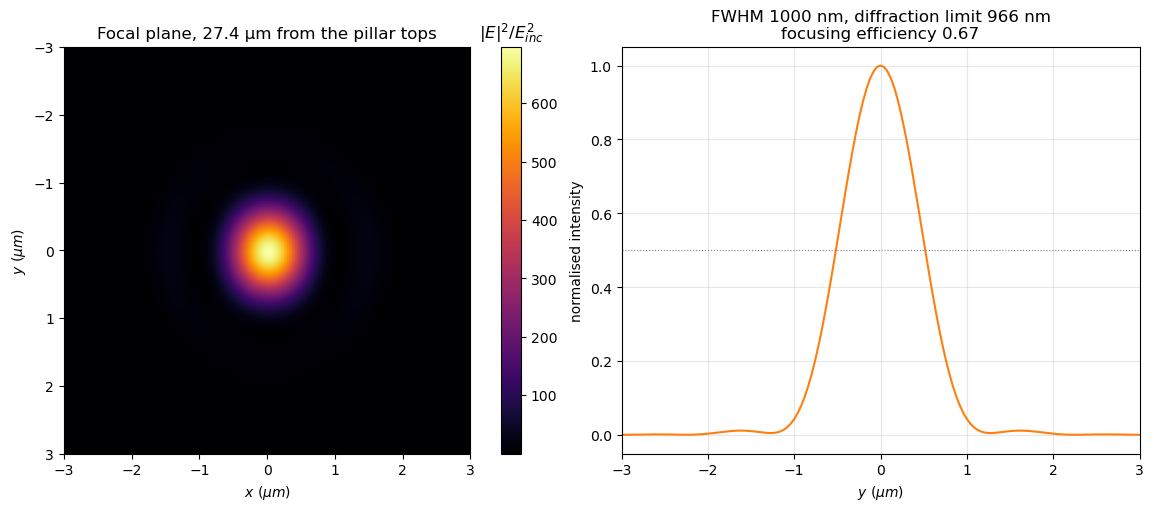

In [12]:
focal = np.sum(np.abs(propagate(u_exit, pixel_size, wavelength, d_focus)) ** 2, axis=0) / e_inc ** 2
cut = focal[i_axis, :] / focal[i_axis, :].max()
above = np.flatnonzero(cut >= 0.5)
fwhm = (above[-1] - above[0] + 1) * pixel_size
xx, yy = np.meshgrid((np.arange(nx) - i_axis) * pixel_size, (np.arange(ny) - i_axis) * pixel_size, indexing="ij")
spot = np.hypot(xx, yy) <= 3 * fwhm
efficiency = focal[spot].sum() * pixel_size ** 2 / (n_substrate * np.pi * (aperture / 2) ** 2)
print(f"Focal spot FWHM {fwhm * 1e3:.0f} nm (diffraction limit {dl_fwhm * 1e3:.0f} nm); "
      f"focusing efficiency {efficiency:.3f}; peak intensity {focal.max():.0f} x incident")

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
im = ax_a.imshow(focal.T, cmap="inferno", extent=[-transverse / 2, transverse / 2, transverse / 2, -transverse / 2])
ax_a.set_xlim(-3, 3); ax_a.set_ylim(3, -3)
ax_a.set_xlabel(r"$x~(\mu m)$"); ax_a.set_ylabel(r"$y~(\mu m)$")
ax_a.set_title(f"Focal plane, {f_measured:.1f} μm from the pillar tops")
fig.colorbar(im, ax=ax_a, fraction=0.046).ax.set_title(r"$|E|^2/E_{inc}^2$")
ax_b.plot((np.arange(ny) - i_axis) * pixel_size, cut, color="tab:orange")
ax_b.axhline(0.5, color="grey", ls=":", lw=0.8)
ax_b.set_xlim(-3, 3); ax_b.set_xlabel(r"$y~(\mu m)$"); ax_b.set_ylabel("normalised intensity")
ax_b.set_title(f"FWHM {fwhm * 1e3:.0f} nm, diffraction limit {dl_fwhm * 1e3:.0f} nm\n"
               f"focusing efficiency {efficiency:.2f}")
ax_b.grid(True, alpha=0.3)
fig.savefig(f"{OUTPUT_DIR}/metalens_large_spot.png", dpi=200)
print(f"Saved output/{NAME}/metalens_large_setup.png, _library.png, _field.png, _spot.png")
plt.show()